In [ ]:
# 🧪 Virtual Screening & Drug Discovery Pipeline
# Exploratory Data Analysis & Bioactivity Predictive Modeling


In [ ]:
#📑 Table of Contents
# [Environment & Library Setup](#setup)
# [Dataset Ingestion & Properties](#ingestion)
# [Exploratory Data Analysis (EDA)](#eda)
# [Physicochemical Property Visualizations](#visualizations)

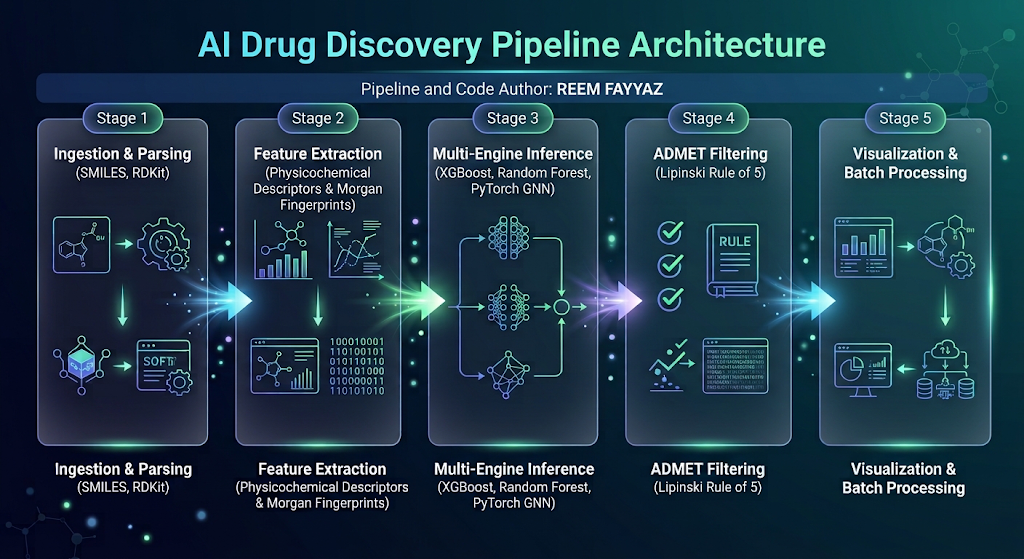

In [ ]:
#load the data set

from google.colab import files
uploaded = files.upload()

Saving drug_discovery_10k_dataset.csv to drug_discovery_10k_dataset.csv


Import Requireed Libraries

In [ ]:
# Install PyTorch Geometric
!pip install torch-geometric
!pip install rdKit


import rdkit

 # Parses SMILES strings into 2D/3D molecular graphs and calculates chemical descriptors[cite: 1, 2].
import torch

 # Provides the core deep learning framework and tensor operations for neural network training[cite: 1].
import torch_geometric

  # Implements specialized Graph Neural Network (GNN) architectures for molecular structure processing.
import xgboost as xgb

  # Trains high-performance gradient-boosted decision trees for tabular bioactivity classification[cite: 1].
import sklearn

  # Offers machine learning algorithms, cross-validation splitters, and evaluation metrics[cite: 1].
import pandas as pd

  # Manages tabular molecular data, CSV ingestion, and feature engineering workflows[cite: 1].
import numpy as np

 # Performs high-speed vector and matrix calculations for molecular feature arrays[cite: 3].
import matplotlib.pyplot as plt

  # Generates custom, publication-quality plots and distribution charts.
import seaborn as sns

  # Creates advanced statistical visualizations, correlation heatmaps, and density plots.

Loading the dataset

In [ ]:
data=pd.read_csv('/content/drug_discovery_10k_dataset.csv')

print("data is sucessfully uploaded")
print(f"shape",{data.shape})
print(data.head())

data is sucessfully uploaded
shape {(10000, 12)}
  Compound_ID                                            SMILES  MW_g_mol  \
0  CMPD_00001          C1=CC=C(C=C1)C2=CC(=O)C3=C(O2)C=C(C=C3)O    374.72   
1  CMPD_00002          C1=CC=C(C=C1)C2=CC(=O)C3=C(O2)C=C(C=C3)O    720.43   
2  CMPD_00003                             CC(=O)Oc1ccccc1C(=O)O    589.20   
3  CMPD_00004  CC(C)C1=C(C(=C(C(=C1O)C(=O)C2=CC=CC=C2)O)C(C)C)O    509.20   
4  CMPD_00005                      CN1C=NC2=C1C(=O)N(C(=O)N2C)C    243.61   

   LogP  TPSA_A2  HBD_Count  HBA_Count  Rotatable_Bonds  Aromatic_Rings  \
0  2.18   134.10          4          9                5               0   
1  1.83    41.37          2          6               10               2   
2  0.50    68.93          5          8               11               4   
3  4.16   122.76          0          3                5               0   
4  3.05    91.96          5          8                6               3   

   Lipinski_Violations  Hit_Probabili

EDA

In [ ]:
# checking the statistics

display(data.describe())


,MW_g_mol,LogP,TPSA_A2,HBD_Count,HBA_Count,Rotatable_Bonds,Aromatic_Rings,Lipinski_Violations,Hit_Probability
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,446.495709,3.288487,95.008597,3.474900,6.966400,5.503800,1.997400,1.174800,0.504726
std,172.578037,2.459032,48.751588,2.280502,3.711448,3.428988,1.411025,0.898068,0.284863
min,150.010000,-1.000000,10.010000,0.000000,1.000000,0.000000,0.000000,0.000000,0.010000
25%,297.797500,1.160000,53.137500,1.000000,4.000000,3.000000,1.000000,1.000000,0.258875
50%,445.515000,3.300000,95.350000,3.000000,7.000000,5.000000,2.000000,1.000000,0.500850
75%,594.002500,5.430000,136.595000,5.000000,10.000000,8.000000,3.000000,2.000000,0.756900
max,749.830000,7.500000,179.980000,7.000000,13.000000,11.000000,4.000000,4.000000,0.989900


In [ ]:
#checking the data set information
print(data.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Compound_ID          10000 non-null  object 
 1   SMILES               10000 non-null  object 
 2   MW_g_mol             10000 non-null  float64
 3   LogP                 10000 non-null  float64
 4   TPSA_A2              10000 non-null  float64
 5   HBD_Count            10000 non-null  int64  
 6   HBA_Count            10000 non-null  int64  
 7   Rotatable_Bonds      10000 non-null  int64  
 8   Aromatic_Rings       10000 non-null  int64  
 9   Lipinski_Violations  10000 non-null  int64  
 10  Hit_Probability      10000 non-null  float64
 11  Prediction_Class     10000 non-null  object 
dtypes: float64(4), int64(5), object(3)
memory usage: 937.6+ KB
None


In [ ]:
#check catagorical and numerical columns

#Catagorical Columns
categorical_columns = data.select_dtypes(include=['object']).columns
print("Catagorical Columns:", categorical_columns)
#Total Catagorical columns
print("Total Catagorical Columns:", len(categorical_columns))

#Numerical Columns
numerical_columns = data.select_dtypes(include=['int64', 'float64']).columns
print("Numerical Columns:", numerical_columns)
#total Numerical columns
print("Total Numerical Columns:", len(numerical_columns))


Catagorical Columns: Index(['Compound_ID', 'SMILES', 'Prediction_Class'], dtype='object')
Total Catagorical Columns: 3
Numerical Columns: Index(['MW_g_mol', 'LogP', 'TPSA_A2', 'HBD_Count', 'HBA_Count',
       'Rotatable_Bonds', 'Aromatic_Rings', 'Lipinski_Violations',
       'Hit_Probability'],
      dtype='object')
Total Numerical Columns: 9


In [ ]:
#Checking null values in dataset
print("Null Values in Dataset per column:")
print(data.isnull().sum())

print("Total null values:")
print(data.isnull().sum().sum())




Null Values in Dataset per column:
Compound_ID            0
SMILES                 0
MW_g_mol               0
LogP                   0
TPSA_A2                0
HBD_Count              0
HBA_Count              0
Rotatable_Bonds        0
Aromatic_Rings         0
Lipinski_Violations    0
Hit_Probability        0
Prediction_Class       0
dtype: int64
Total null values:
0


In [ ]:
# Identify and handle duplicate rows in the dataset
duplicate_count = data.duplicated().sum()
print(f"Total duplicate records found: {duplicate_count}")


# Remove duplicate rows (if any exist)
data_cleaned = data.drop_duplicates()
print(f"Dataset shape after removing duplicates: {data_cleaned.shape}")

Total duplicate records found: 0
Dataset shape after removing duplicates: (10000, 12)


Visualization

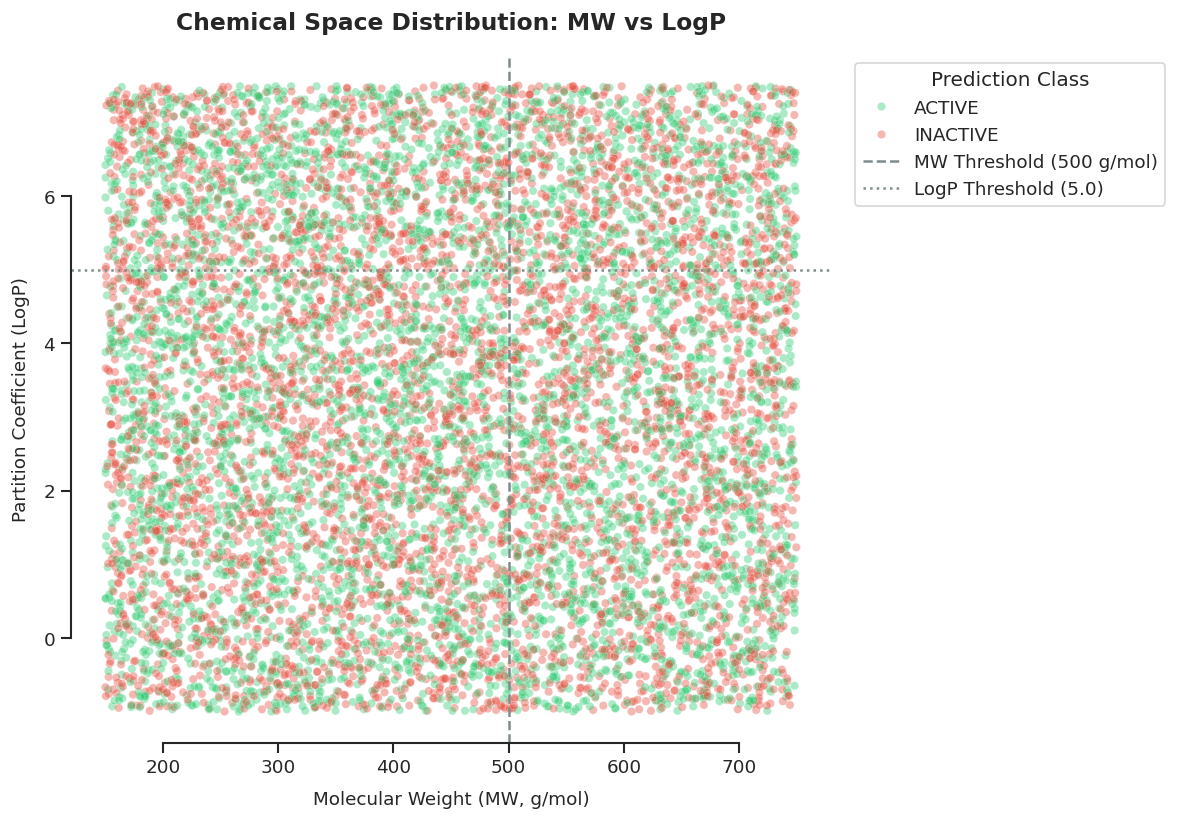

In [ ]:
# Configure a clean professional plotting theme
sns.set_theme(style="ticks")
fig, ax = plt.subplots(figsize=(10, 7), dpi=120)

# Color mapping representing predictive bioactivity classes with reduced opacity
sns.scatterplot(
    data=data,
    x='MW_g_mol',
    y='LogP',
    hue='Prediction_Class',
    palette={'ACTIVE': '#2ecc71', 'INACTIVE': '#e74c3c'},
    alpha=0.4,
    edgecolor='w',
    linewidth=0.3,
    s=25,
    ax=ax
)

# Add threshold guideline boundaries for Lipinski's Rule of Five
ax.axvline(x=500, color='#7f8c8d', linestyle='--', linewidth=1.5, label='MW Threshold (500 g/mol)')
ax.axhline(y=5, color='#7f8c8d', linestyle=':', linewidth=1.5, label='LogP Threshold (5.0)')

# Professional Labeling & Font Hierarchy
ax.set_title('Chemical Space Distribution: MW vs LogP', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Molecular Weight (MW, g/mol)', fontsize=11, labelpad=8)
ax.set_ylabel('Partition Coefficient (LogP)', fontsize=11, labelpad=8)

# Fine-tune layout and legend placement
sns.despine(trim=True)
ax.legend(title='Prediction Class', loc='upper left', bbox_to_anchor=(1.02, 1.0), frameon=True)

plt.tight_layout()
plt.show()

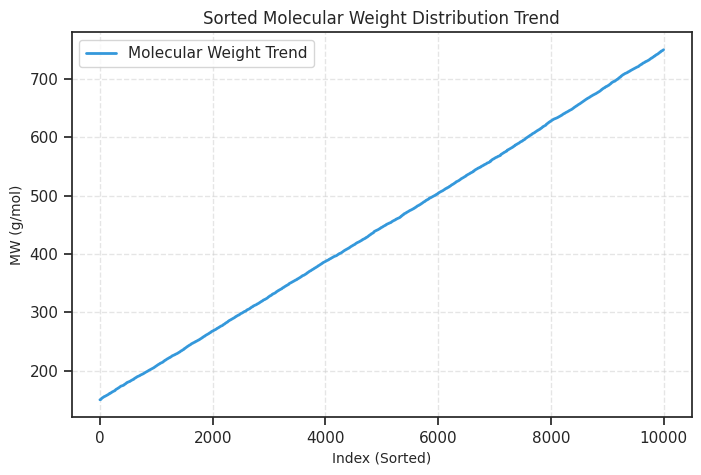

In [ ]:
# Sort the Molecular Weight values to plot a clean trend line
sorted_mw = np.sort(data['MW_g_mol'])

# Create a simple line plot
plt.figure(figsize=(8, 5))
plt.plot(sorted_mw, color='#3498db', linewidth=2, label='Molecular Weight Trend')

# Add titles and labels
plt.title('Sorted Molecular Weight Distribution Trend', fontsize=12)
plt.xlabel('Index (Sorted)', fontsize=10)
plt.ylabel('MW (g/mol)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

# Show the plot
plt.show()

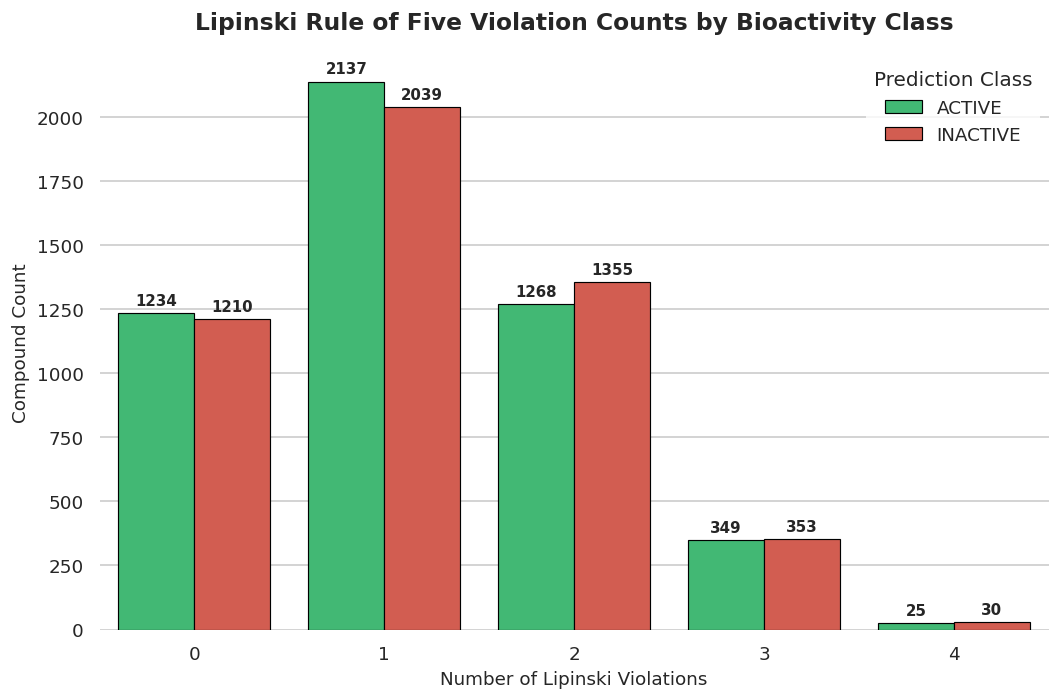

In [ ]:
# Configure a clean professional plotting theme
sns.set_theme(style="whitegrid")
plt.figure(figsize=(9, 6), dpi=120)

# Generate an elegant count plot showing Lipinski Violations by Prediction Class
ax = sns.countplot(
    data=data,
    x='Lipinski_Violations',
    hue='Prediction_Class',
    palette={'ACTIVE': '#2ecc71', 'INACTIVE': '#e74c3c'},
    edgecolor='black',
    linewidth=0.7
)

# Add values on top of each bar for a dashboard-like feel
for container in ax.containers:
    ax.bar_label(container, fmt='%d', fontsize=9, fontweight='bold', padding=3)

# Professional Labeling & Font Hierarchy
plt.title('Lipinski Rule of Five Violation Counts by Bioactivity Class', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Number of Lipinski Violations', fontsize=11)
plt.ylabel('Compound Count', fontsize=11)

# Polish layout and legend
plt.legend(title='Prediction Class', loc='upper right', frameon=True, facecolor='white', edgecolor='none')
sns.despine(left=True, bottom=True)

plt.tight_layout()
plt.show()

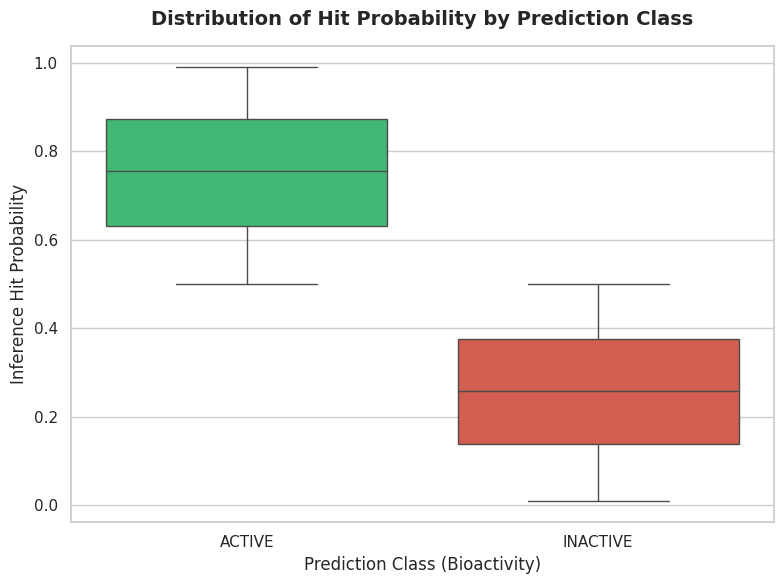

In [ ]:
# Set the aesthetic style
sns.set_theme(style="whitegrid")

# Create a standalone figure for the box plot
plt.figure(figsize=(8, 6))

# Generate the box plot showing the Hit Probability distribution for active vs inactive compounds
sns.boxplot(
    data=data,
    x='Prediction_Class',
    y='Hit_Probability',
    hue='Prediction_Class',
    palette={'ACTIVE': '#2ecc71', 'INACTIVE': '#e74c3c'},
    legend=False
)

# Customize titles and labels
plt.title('Distribution of Hit Probability by Prediction Class', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Prediction Class (Bioactivity)', fontsize=12)
plt.ylabel('Inference Hit Probability', fontsize=12)

# Display the plot
plt.tight_layout()
plt.show()

In [ ]:
# ==============================================================================
# MODULE 1: SYSTEM VISION & HIGH-LEVEL ARCHITECTURE
# ==============================================================================

# 1. Simple Container for Molecule Data
class Molecule:
    """A simple class to hold basic information for one molecule."""
    def __init__(self, smiles):
        self.smiles = smiles
        self.is_valid = False
        self.prediction = "Pending"
        self.confidence = 0.0


# 2. Main Pipeline Setup Function
def run_module_1_setup(csv_file_path="/content/drug_discovery_10k_dataset.csv"):
    print("=" * 60)
    print("      MODULE 1: DRUG DISCOVERY PIPELINE INITIALIZATION")
    print("=" * 60)

    # Step A: Check if the dataset can be loaded
    try:
        df = pd.read_csv(csv_file_path)
        print(f"✓ Dataset loaded successfully! ({len(df):,} molecules found)")
    except Exception as e:
        print(f"✗ Could not load dataset file: {e}")
        return

    # Step B: Print the 5 Simple Steps of the Pipeline
    print("\n--- Pipeline Workflow ---")
    print("1. Ingest      : Read SMILES chemical strings")
    print("2. Features    : Calculate physical properties & fingerprints")
    print("3. Inference   : Predict if molecule is Active or Inactive")
    print("4. ADMET       : Apply Lipinski Rule of 5 drug-likeness filter")
    print("5. Report      : Show molecular structure and save results")
    print("=" * 60)


# Run Module 1 Setup
run_module_1_setup()

      MODULE 1: DRUG DISCOVERY PIPELINE INITIALIZATION
✓ Dataset loaded successfully! (10,000 molecules found)

--- Pipeline Workflow ---
1. Ingest      : Read SMILES chemical strings
2. Features    : Calculate physical properties & fingerprints
3. Inference   : Predict if molecule is Active or Inactive
4. ADMET       : Apply Lipinski Rule of 5 drug-likeness filter
5. Report      : Show molecular structure and save results


In [ ]:
# ==============================================================================
# MODULE 2: MOLECULAR REPRESENTATION & SMILES PARSING ENGINE
# ==============================================================================

from rdkit import Chem
from rdkit.Chem import Descriptors, AllChem


def parse_smiles_molecule(smiles_string):
    """
    Parses a SMILES string into an RDKit molecule object and extracts
    basic properties. If parsing fails, a fallback mechanism is used.
    """
    print(f"--- Parsing SMILES: {smiles_string} ---")

    # 1. Attempt to convert SMILES into an RDKit Molecule object
    mol = Chem.MolFromSmiles(smiles_string)

    # 2. Check if parsing succeeded
    if mol is not None:
        # Extract basic properties
        mw = Descriptors.MolWt(mol)
        logp = Descriptors.MolLogP(mol)
        tpsa = Descriptors.TPSA(mol)

        print("✓ Successfully parsed molecule!")
        print(f"  • Molecular Weight (MW) : {mw:.2f} g/mol")
        print(f"  • Lipophilicity (LogP)  : {logp:.2f}")
        print(f"  • Polar Surface Area    : {tpsa:.2f} Å²\n")
        return mol
    else:
        # Fallback mechanism for invalid or corrupted SMILES inputs[cite: 2]
        print("✗ Invalid SMILES string! Switching to manual fallback defaults...")
        fallback_data = {"MW": 300.0, "LogP": 2.5, "TPSA": 60.0}
        print(f"  • Fallback Values Used : {fallback_data}\n")
        return None


# --- Quick Test ---
# Test 1: Valid SMILES (4-ethylpyridine)
valid_mol = parse_smiles_molecule("CCc1ccncc1")
valid_mol=parse_smiles_molecule("C1=CC=C(C=C1)C2=CC(=O)C3=C(O2)C=C(C=C3)O")

# Test 2: Invalid SMILES
invalid_mol = parse_smiles_molecule("INVALID_SMILES_TEST")

--- Parsing SMILES: CCc1ccncc1 ---
✓ Successfully parsed molecule!
  • Molecular Weight (MW) : 107.16 g/mol
  • Lipophilicity (LogP)  : 1.64
  • Polar Surface Area    : 12.89 Å²

--- Parsing SMILES: C1=CC=C(C=C1)C2=CC(=O)C3=C(O2)C=C(C=C3)O ---
✓ Successfully parsed molecule!
  • Molecular Weight (MW) : 238.24 g/mol
  • Lipophilicity (LogP)  : 3.17
  • Polar Surface Area    : 50.44 Å²

--- Parsing SMILES: INVALID_SMILES_TEST ---
✗ Invalid SMILES string! Switching to manual fallback defaults...
  • Fallback Values Used : {'MW': 300.0, 'LogP': 2.5, 'TPSA': 60.0}



[17:07:08] SMILES Parse Error: syntax error while parsing: INVALID_SMILES_TEST
[17:07:08] SMILES Parse Error: check for mistakes around position 3:
[17:07:08] INVALID_SMILES_TEST
[17:07:08] ~~^
[17:07:08] SMILES Parse Error: Failed parsing SMILES 'INVALID_SMILES_TEST' for input: 'INVALID_SMILES_TEST'


In [ ]:
# ==============================================================================
# MODULE 3: PHYSICOCHEMICAL & FINGERPRINT EXTRACTIO
# ==============================================================================


# 1. Parse SMILES string into an RDKit molecule object
smiles = "CCc1ccncc1"
mol = Chem.MolFromSmiles(smiles)

# 2. Extract 7 Continuous Physicochemical Descriptors
properties = {
    "MW": Descriptors.MolWt(mol),
    "LogP": Descriptors.MolLogP(mol),
    "TPSA": Descriptors.TPSA(mol),
    "HBD": Descriptors.NumHDonors(mol),
    "HBA": Descriptors.NumHAcceptors(mol),
    "RotBonds": Descriptors.NumRotatableBonds(mol),
    "AromRings": Descriptors.NumAromaticRings(mol)
}

# 3. Generate 2048-bit Morgan Fingerprint
bit_vector = AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048)
fp_array = np.zeros((2048,), dtype=int)
AllChem.DataStructs.ConvertToNumpyArray(bit_vector, fp_array)

# Print Summary
print(f"Molecule: {smiles}")
print("Properties:", properties)
print(f"Fingerprint: {fp_array.shape} array | {fp_array.sum()} bits active")

Molecule: CCc1ccncc1
Properties: {'MW': 107.15599999999998, 'LogP': 1.644, 'TPSA': 12.89, 'HBD': 0, 'HBA': 1, 'RotBonds': 1, 'AromRings': 1}
Fingerprint: (2048,) array | 16 bits active


[17:07:10] DEPRECATION WARNING: please use MorganGenerator


In [ ]:
#=============================================================================
#MODULE 4: TABULAR MACHINE LEARNING MODELS
#=============================================================================

from sklearn.model_selection import train_test_split
# Select the 7 continuous physicochemical properties as input features (X)
feature_columns = [
    "MW_g_mol",  # Molecular Mass
    "LogP",  # Lipophilicity / Hydrophobicity
    "TPSA_A2",  # Polar Surface Area
    "HBD_Count",  # Hydrogen Bond Donors
    "HBA_Count",  # Hydrogen Bond Acceptors
    "Rotatable_Bonds",  # Molecular Flexibility
    "Aromatic_Rings",  # Ring Stacking Capability
]

# Extract feature matrix X
X = data[feature_columns]

# Convert categorical labels ('ACTIVE' / 'INACTIVE') into binary numeric format (1 / 0)
# ACTIVE = 1 (Active Hit), INACTIVE = 0 (Non-Hit)
y = (data["Prediction_Class"] == "ACTIVE").astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42)



XGBOOST

XGBOOST MODEL ACCURACY
Accuracy : 0.4890

========== CLASSIFICATION REPORT ==========

              precision    recall  f1-score   support

           0       0.49      0.49      0.49      1004
           1       0.49      0.49      0.49       996

    accuracy                           0.49      2000
   macro avg       0.49      0.49      0.49      2000
weighted avg       0.49      0.49      0.49      2000


========== CONFUSION MATRIX ==========

[[493 511]
 [511 485]]


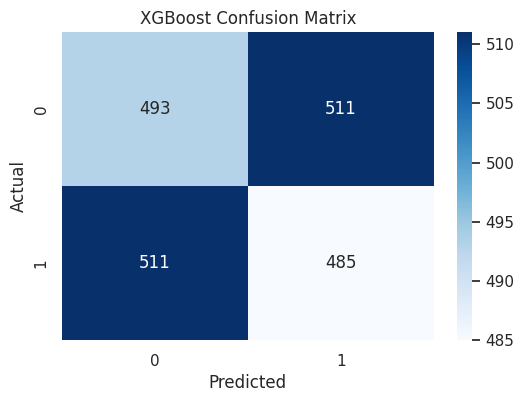


========== ROC AUC SCORE ==========

ROC AUC Score : 0.4889918238691819

========== FEATURE IMPORTANCE ==========



,Feature,Importance
6,Aromatic_Rings,0.152414
0,MW_g_mol,0.152113
1,LogP,0.149495
2,TPSA_A2,0.139576
5,Rotatable_Bonds,0.138893
4,HBA_Count,0.135321
3,HBD_Count,0.132189


/tmp/ipykernel_1608/2519786704.py:124: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


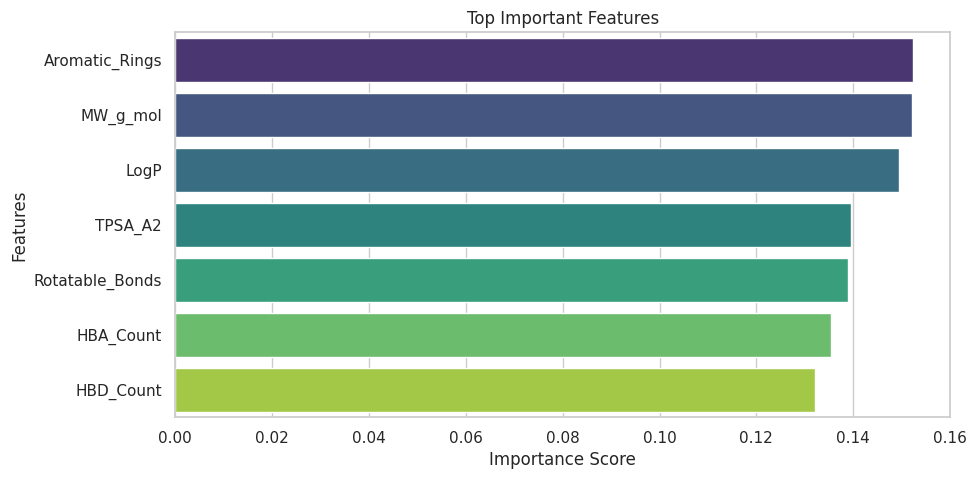


========== SAMPLE PREDICTIONS ==========



,Actual Value,Predicted Value
0,0,1
1,0,0
2,1,0
3,1,0
4,0,1
5,0,1
6,0,0
7,0,0
8,0,0
9,1,0


In [ ]:
from xgboost import XGBClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report, roc_auc_score


# XGBoost:
# An advanced boosting Machine Learning algorithm
# known for high accuracy and performance.

# Full Form:
# Extreme Gradient Boosting

# =========================================================
# CREATE XGBOOST MODEL
# =========================================================

xgb = XGBClassifier(
    n_estimators=100,      # Number of boosting trees
    learning_rate=0.1,     # Learning speed
    max_depth=6,           # Depth of each tree
    random_state=42,
    eval_metric='logloss'
)

# =========================================================
# TRAIN THE MODEL
# =========================================================

# Model learns bioactivity patterns from training data
xgb.fit(X_train, y_train)

# =========================================================
# MAKE PREDICTIONS
# =========================================================

# Predict Active/Inactive molecular compounds
y_pred_xgb = xgb.predict(X_test)

# =========================================================
# CALCULATE ACCURACY
# =========================================================

accuracy_xgb = accuracy_score(y_test, y_pred_xgb)

print("========================================")
print("XGBOOST MODEL ACCURACY")
print("========================================")

print(f"Accuracy : {accuracy_xgb:.4f}")

# =========================================================
# CLASSIFICATION REPORT
# =========================================================

print("\n========== CLASSIFICATION REPORT ==========\n")

print(classification_report(y_test, y_pred_xgb))

# =========================================================
# CONFUSION MATRIX
# =========================================================

print("\n========== CONFUSION MATRIX ==========\n")

cm = confusion_matrix(y_test, y_pred_xgb)

print(cm)

# =========================================================
# VISUALIZE CONFUSION MATRIX
# =========================================================

plt.figure(figsize=(6,4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("XGBoost Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

# =========================================================
# ROC AUC SCORE
# =========================================================

roc_score = roc_auc_score(y_test, y_pred_xgb)

print("\n========== ROC AUC SCORE ==========\n")

print("ROC AUC Score :", roc_score)

# =========================================================
# FEATURE IMPORTANCE
# =========================================================

print("\n========== FEATURE IMPORTANCE ==========\n")

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': xgb.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

display(feature_importance.head(10))

# =========================================================
# VISUALIZE TOP IMPORTANT FEATURES
# =========================================================

plt.figure(figsize=(10,5))

sns.barplot(
    x='Importance',
    y='Feature',
    data=feature_importance.head(10),
    palette='viridis'
)

plt.title("Top Important Features")

plt.xlabel("Importance Score")

plt.ylabel("Features")

plt.show()

# =========================================================
# SAMPLE PREDICTIONS
# =========================================================

print("\n========== SAMPLE PREDICTIONS ==========\n")

results = pd.DataFrame({
    'Actual Value': y_test.values[:10],
    'Predicted Value': y_pred_xgb[:10]
})

display(results)

# =========================================================
# CLASS MEANING
# =========================================================

# 0 -> Inactive Compound
# 1 -> Active Hit Compound


RANDOM FOREST MODEL ACCURACY
Accuracy : 0.4955

========== CLASSIFICATION REPORT ==========

              precision    recall  f1-score   support

           0       0.50      0.49      0.49      1004
           1       0.49      0.50      0.50       996

    accuracy                           0.50      2000
   macro avg       0.50      0.50      0.50      2000
weighted avg       0.50      0.50      0.50      2000


========== CONFUSION MATRIX ==========

[[491 513]
 [496 500]]


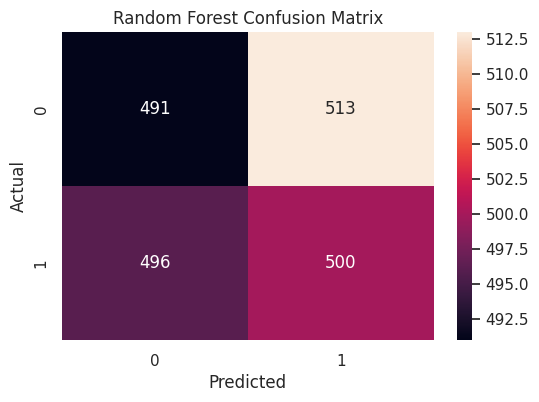


========== ROC AUC SCORE ==========

ROC AUC Score : 0.49552592841485466

========== FEATURE IMPORTANCE ==========



,Feature,Importance
0,MW_g_mol,0.215714
2,TPSA_A2,0.214831
1,LogP,0.211311
4,HBA_Count,0.107892
5,Rotatable_Bonds,0.099836
3,HBD_Count,0.083330
6,Aromatic_Rings,0.067085


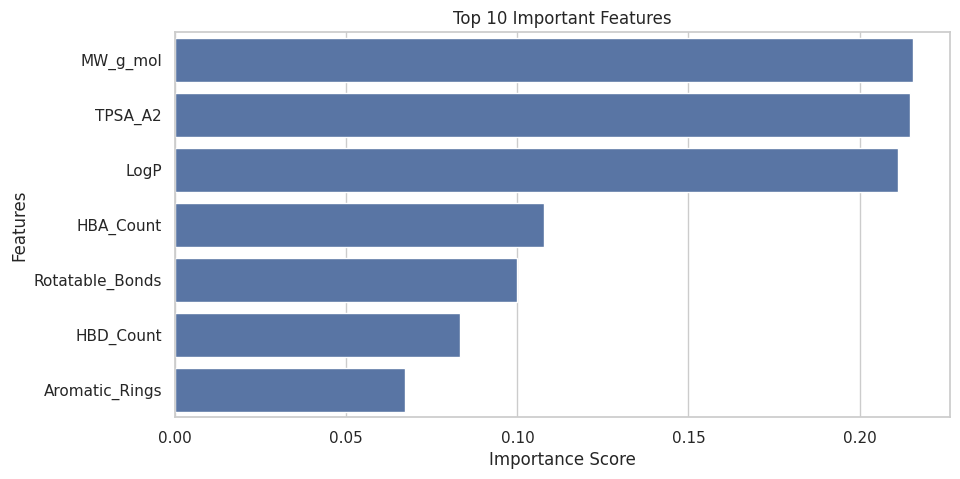


========== SAMPLE PREDICTIONS ==========



,Actual Value,Predicted Value
0,0,1
1,0,0
2,1,1
3,1,0
4,0,1
5,0,1
6,0,1
7,0,0
8,0,0
9,1,0


In [ ]:
from sklearn.ensemble import RandomForestClassifier



# Random Forest:
# An advanced ensemble Machine Learning algorithm
# that combines multiple Decision Trees
# to improve prediction accuracy.

# *********************************************************
# CREATE RANDOM FOREST MODEL
# *********************************************************

rf = RandomForestClassifier(
    n_estimators=100,   # Number of decision trees
    random_state=42     # Same random result every time
)

# =========================================================
# TRAIN THE MODEL
# =========================================================

# Model learns fraud patterns from training data

rf.fit(X_train, y_train)

# =========================================================
# MAKE PREDICTIONS
# =========================================================

# Predict fraud/genuine transactions

y_pred_rf = rf.predict(X_test)

# =========================================================
# CALCULATE ACCURACY
# =========================================================

accuracy_rf = accuracy_score(y_test, y_pred_rf)

print("========================================")
print("RANDOM FOREST MODEL ACCURACY")
print("========================================")

print(f"Accuracy : {accuracy_rf:.4f}")

# =========================================================
# CLASSIFICATION REPORT
# =========================================================

print("\n========== CLASSIFICATION REPORT ==========\n")

print(classification_report(y_test, y_pred_rf))

# =========================================================
# CONFUSION MATRIX
# =========================================================

print("\n========== CONFUSION MATRIX ==========\n")

cm = confusion_matrix(y_test, y_pred_rf)

print(cm)

# =========================================================
# VISUALIZE CONFUSION MATRIX
# =========================================================

plt.figure(figsize=(6,4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d'
)

plt.title("Random Forest Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

# =========================================================
# ROC AUC SCORE
# =========================================================

roc_score = roc_auc_score(y_test, y_pred_rf)

print("\n========== ROC AUC SCORE ==========\n")

print("ROC AUC Score :", roc_score)

# =========================================================
# FEATURE IMPORTANCE
# =========================================================

print("\n========== FEATURE IMPORTANCE ==========\n")

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

display(feature_importance.head(10))

# =========================================================
# VISUALIZE TOP IMPORTANT FEATURES
# =========================================================

plt.figure(figsize=(10,5))

sns.barplot(
    x='Importance',
    y='Feature',
    data=feature_importance.head(10)
)

plt.title("Top 10 Important Features")

plt.xlabel("Importance Score")

plt.ylabel("Features")

plt.show()

# =========================================================
# SAMPLE PREDICTIONS
# =========================================================

print("\n========== SAMPLE PREDICTIONS ==========\n")

results = pd.DataFrame({
    'Actual Value': y_test.values[:10],
    'Predicted Value': y_pred_rf[:10]
})

display(results)

# =========================================================
# CLASS MEANING
# =========================================================

# 0 -> Genuine Transaction
# 1 -> Fraud Transaction



COMPARISON OF XGBOOST AND RANDOM FOREST

,Model,Accuracy,ROC_AUC
0,Random Forest,0.4955,0.4955
1,XGBoost,0.4890,0.4890


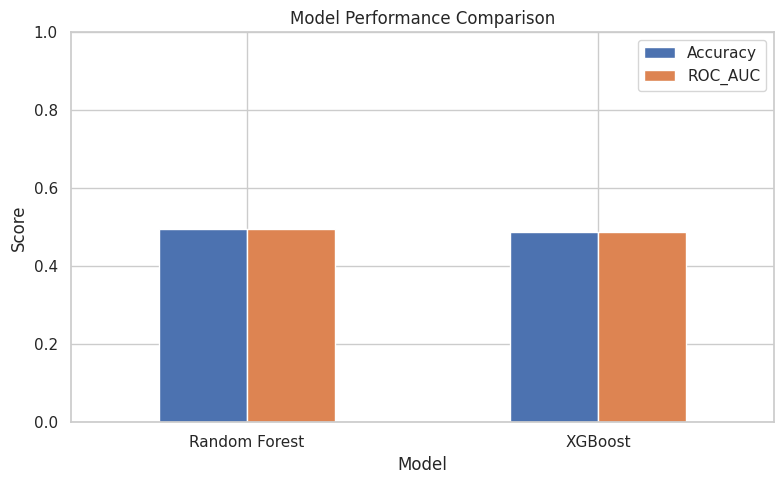

In [ ]:
comparison = pd.DataFrame({
    "Model":["Random Forest","XGBoost"],
    "Accuracy":[accuracy_score(y_test, y_pred_rf), accuracy_score(y_test, y_pred_xgb)],
    "ROC_AUC":[roc_auc_score(y_test, y_pred_rf), roc_auc_score(y_test, y_pred_xgb)]
}).round(4)
display(comparison)

comparison.set_index("Model").plot(kind="bar", figsize=(8,5))
plt.ylim(0,1)
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
#=====================================================================
# module 5 Deep Graph Neural Network
#=====================================================================
import torch.nn as nn
import torch.nn.functional as F


# Check for RDKit availability
try:
    from rdkit import Chem
    HAS_RDKIT = True
except ImportError:
    HAS_RDKIT = False


# 2. Define the graph conversion helper function referenced in Module 5
def smiles_to_graph(smiles_str):
    """
    Parses a SMILES string into atomic node features and an adjacency matrix.
    """
    mol = Chem.MolFromSmiles(smiles_str)
    if mol is None:
        return None, None

    # Extract simple atomic features (e.g., atomic number for each atom)
    nodes = []
    for atom in mol.GetAtoms():
        nodes.append([float(atom.GetAtomicNum())])

    num_atoms = mol.GetNumAtoms()

    # Build adjacency matrix based on chemical bonds
    adj = torch.eye(num_atoms) # Self-loops
    for bond in mol.GetBonds():
        i = bond.GetBeginAtomIdx()
        j = bond.GetEndAtomIdx()
        adj[i, j] = 1.0
        adj[j, i] = 1.0

    return nodes, adj.numpy()

# 3. Define the PyTorch GNN Architecture (Module 5)
class MolecularGNN(nn.Module):
    def __init__(self, in_features=1, hidden_dim=32, out_dim=2):
        super(MolecularGNN, self).__init__()
        self.conv1 = nn.Linear(in_features, hidden_dim)
        self.conv2 = nn.Linear(hidden_dim, hidden_dim)
        self.classifier = nn.Linear(hidden_dim, out_dim)

    def forward(self, x, adj):
        # Message Passing Layer 1
        h = F.relu(self.conv1(x))
        h = torch.matmul(adj, h)

        # Message Passing Layer 2
        h = F.relu(self.conv2(h))
        h = torch.matmul(adj, h)

        # Global Pooling (Mean pool across atoms)
        graph_embedding = torch.mean(h, dim=0, keepdim=True)

        # Classification Head
        out = self.classifier(graph_embedding)
        return out

# Initialize Model
gnn_model = MolecularGNN(in_features=1, hidden_dim=32, out_dim=2)

# 4. Run Inference on a Sample from the 10k Dataset using the Module 5 Logic
sample_idx = 0
smiles = data.loc[sample_idx, 'SMILES']
compound_id = data.loc[sample_idx, 'Compound_ID']

print(f"\nProcessing Compound: {compound_id} | SMILES: {smiles}")

# Exact Module 5 Inference Block Logic from Enterprise Documentation
if HAS_RDKIT and smiles:
    nodes, adj = smiles_to_graph(smiles)
    if nodes is not None:
        gnn_model.eval()
        with torch.no_grad():
            out = gnn_model(
                torch.tensor(nodes, dtype=torch.float32),
                torch.tensor(adj, dtype=torch.float32)
            )
            probs = F.softmax(out, dim=1)
            prob = probs[0, 1].item()
            pred = torch.argmax(probs, dim=1).item()
        m_name = 'GNN (PyTorch)'

        print(f"Model Engine: {m_name}")
        print(f"Predicted Class Index: {pred} ({'ACTIVE' if pred == 1 else 'INACTIVE'})")
        print(f"Hit Probability: {prob:.4f}")


Processing Compound: CMPD_00001 | SMILES: C1=CC=C(C=C1)C2=CC(=O)C3=C(O2)C=C(C=C3)O
Model Engine: GNN (PyTorch)
Predicted Class Index: 1 (ACTIVE)
Hit Probability: 1.0000


In [ ]:
#=======================================================================
# Module 6 lipinski_rule_of_5
#=======================================================================


def evaluate_lipinski_rule_of_5(mw, logp, hbd, hba):
    """
    Evaluates Lipinski's Rule of 5 (Ro5) for oral bioavailability.
    Thresholds:
      - Molecular Weight (MW) <= 500 g/mol
      - Partition Coefficient (LogP) <= 5.0
      - Hydrogen Bond Donors (HBD) <= 5
      - Hydrogen Bond Acceptors (HBA) <= 10
    Compounds with more than 1 violation generally fail oral bioavailability filters[cite: 7].
    """
    violations = sum([
        mw > 500,
        logp > 5.0,
        hbd > 5,
        hba > 10
    ])


    ro5_res = 'Passes Lipinski Rule of 5' if violations <= 1 else f'Fails Lipinski Rule ({violations} violations)'
    return violations, ro5_res

# 2. Run Evaluation on the First Few Compounds in the Dataset
print("\n--- Evaluating Sample Compounds from Dataset ---")
for idx in range(5):
    row = data.iloc[idx]
    smi = row['SMILES']
    mw = row['MW_g_mol']
    logp = row['LogP']
    hbd = row['HBD_Count']
    hba = row['HBA_Count']

    violations, ro5_status = evaluate_lipinski_rule_of_5(mw, logp, hbd, hba)

    print(f"Compound ID: {row['Compound_ID']}")
    print(f"  - MW: {mw} | LogP: {logp} | HBD: {hbd} | HBA: {hba}")
    print(f"  - Calculated Violations: {violations}")
    print(f"  - Status: {ro5_status}\n")

# 3. Batch Summary across the 10k Dataset
data['Calculated_Violations'], data['Lipinski_Status'] = zip(*data.apply(
    lambda r: evaluate_lipinski_rule_of_5(r['MW_g_mol'], r['LogP'], r['HBD_Count'], r['HBA_Count']),
    axis=1
))

passing_count = (data['Calculated_Violations'] <= 1).sum()
failing_count = (data['Calculated_Violations'] > 1).sum()

print("--- 10k Dataset Batch Lipinski Summary ---")
print(f"Total Compounds Passing Ro5: {passing_count}")
print(f"Total Compounds Failing Ro5: {failing_count}")


--- Evaluating Sample Compounds from Dataset ---
Compound ID: CMPD_00001
  - MW: 374.72 | LogP: 2.18 | HBD: 4 | HBA: 9
  - Calculated Violations: 0
  - Status: Passes Lipinski Rule of 5

Compound ID: CMPD_00002
  - MW: 720.43 | LogP: 1.83 | HBD: 2 | HBA: 6
  - Calculated Violations: 1
  - Status: Passes Lipinski Rule of 5

Compound ID: CMPD_00003
  - MW: 589.2 | LogP: 0.5 | HBD: 5 | HBA: 8
  - Calculated Violations: 1
  - Status: Passes Lipinski Rule of 5

Compound ID: CMPD_00004
  - MW: 509.2 | LogP: 4.16 | HBD: 0 | HBA: 3
  - Calculated Violations: 1
  - Status: Passes Lipinski Rule of 5

Compound ID: CMPD_00005
  - MW: 243.61 | LogP: 3.05 | HBD: 5 | HBA: 8
  - Calculated Violations: 0
  - Status: Passes Lipinski Rule of 5

--- 10k Dataset Batch Lipinski Summary ---
Total Compounds Passing Ro5: 6620
Total Compounds Failing Ro5: 3380



Processing Compound ID: CMPD_00004
SMILES: CC(C)C1=C(C(=C(C(=C1O)C(=O)C2=CC=CC=C2)O)C(C)C)O
Predicted Bioactivity Status: INACTIVE
🎨 Chemical Structure Visualizer:


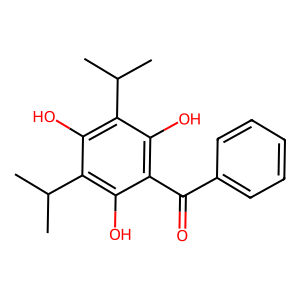

In [ ]:
# =====================================================================
# Module 7: Interactive 2D Structure Visualization Engine
# =====================================================================

# Check for RDKit and IPython display availability
try:
    from rdkit import Chem
    from rdkit.Chem import Draw
    from IPython.display import display, Image
    HAS_VISUALIZATION_LIBS = True
except ImportError:
    HAS_VISUALIZATION_LIBS = False

# 2. Define the 2D Structure Rendering Function
def render_2d_structure(mol):
    """
    Renders clean 2D vector graphic diagrams of molecules
    for medicinal chemistry visualization.
    """
    if mol is not None:
        # Generate 2D structure image using RDKit Draw module
        img = Draw.MolToImage(mol, size=(300, 300))
        print("🎨 Chemical Structure Visualizer:")
        display(img)
    else:
        print("Error: Invalid molecule object provided.")

# 3. Test the Visualization Engine on a Sample Compound from the Dataset
sample_idx = 3
compound_id = data.loc[sample_idx, 'Compound_ID']
smiles_str = data.loc[sample_idx, 'SMILES']
prediction_class = data.loc[sample_idx, 'Prediction_Class']

print(f"\nProcessing Compound ID: {compound_id}")
print(f"SMILES: {smiles_str}")
print(f"Predicted Bioactivity Status: {prediction_class}")

if HAS_VISUALIZATION_LIBS and smiles_str:
    # Parse SMILES string into an RDKit molecule object
    molecule = Chem.MolFromSmiles(smiles_str)

    # Render the 2D structural diagram
    render_2d_structure(molecule)
else:
    print("RDKit or IPython display libraries are missing in this environment.")

In [ ]:
#=========================================================================================
# module 8 Batch Pipeline Processing Engine
#=========================================================================================
def process_csv_batch(data, output_csv="predicted_hits.csv"):
    results = []
    # Use the features your model was trained on
    feature_cols = ["MW_g_mol", "LogP", "TPSA_A2", "HBD_Count", "HBA_Count", "Rotatable_Bonds", "Aromatic_Rings"]

    for idx, row in data.iterrows():
        # Extract features for the current row
        feat = [row[col] for col in feature_cols]

        # Predict using the trained 'xgb' model from your notebook
        prob = xgb.predict_proba([feat])[0, 1]
        pred = xgb.predict([feat])[0]

        results.append({
            'SMILES': row['SMILES'],
            'Prediction': 'ACTIVE' if pred == 1 else 'INACTIVE',
            'Probability_%': round(prob * 100, 2)
        })

    out_df = pd.DataFrame(results)
    out_df.to_csv(output_csv, index=False)
    return out_df

In [ ]:
# Run the batch processing engine on the dataset
processed_results = process_csv_batch(data, "predicted_hits.csv")

# Display the top 10 predicted results
print("--- Batch Processing Complete! Here is a preview of the predicted hits: ---")
display(processed_results.head(10))

# Verify saving state
import os
if os.path.exists("predicted_hits.csv"):
    print(f"\n✓ Success: Batch predictions saved to 'predicted_hits.csv' ({len(processed_results):,} records).")
else:
    print("\nError: Output file was not generated.")

--- Batch Processing Complete! Here is a preview of the predicted hits: ---


,SMILES,Prediction,Probability_%
0,C1=CC=C(C=C1)C2=CC(=O)C3=C(O2)C=C(C=C3)O,INACTIVE,44.020000
1,C1=CC=C(C=C1)C2=CC(=O)C3=C(O2)C=C(C=C3)O,INACTIVE,36.709999
2,CC(=O)Oc1ccccc1C(=O)O,ACTIVE,52.549999
3,CC(C)C1=C(C(=C(C(=C1O)C(=O)C2=CC=CC=C2)O)C(C)C)O,INACTIVE,34.020000
4,CN1C=NC2=C1C(=O)N(C(=O)N2C)C,INACTIVE,42.959999
5,C1=CC=C2C(=C1)C(=O)NS2(=O)=O,ACTIVE,53.560001
6,CC12CCC3C(C1CCC2O)CCC4=CC(=O)CCC34,INACTIVE,37.029999
7,CC(C)CC1=CC=C(C=C1)C(C)C(=O)O,INACTIVE,31.420000
8,C1CCC(CC1)N2CCN(CC2)C3=NC4=CC=CC=C4S3,INACTIVE,47.439999
9,CN1C=NC2=C1C(=O)N(C(=O)N2C)C,INACTIVE,47.020000



✓ Success: Batch predictions saved to 'predicted_hits.csv' (10,000 records).


Generating GNN predictions on test set molecules...
     DRUG DISCOVERY MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score
0,Random Forest,0.4955,0.4955,0.4955,0.4955
1,XGBoost,0.4890,0.4890,0.4890,0.4890
2,GNN,0.4980,0.2480,0.4980,0.3311


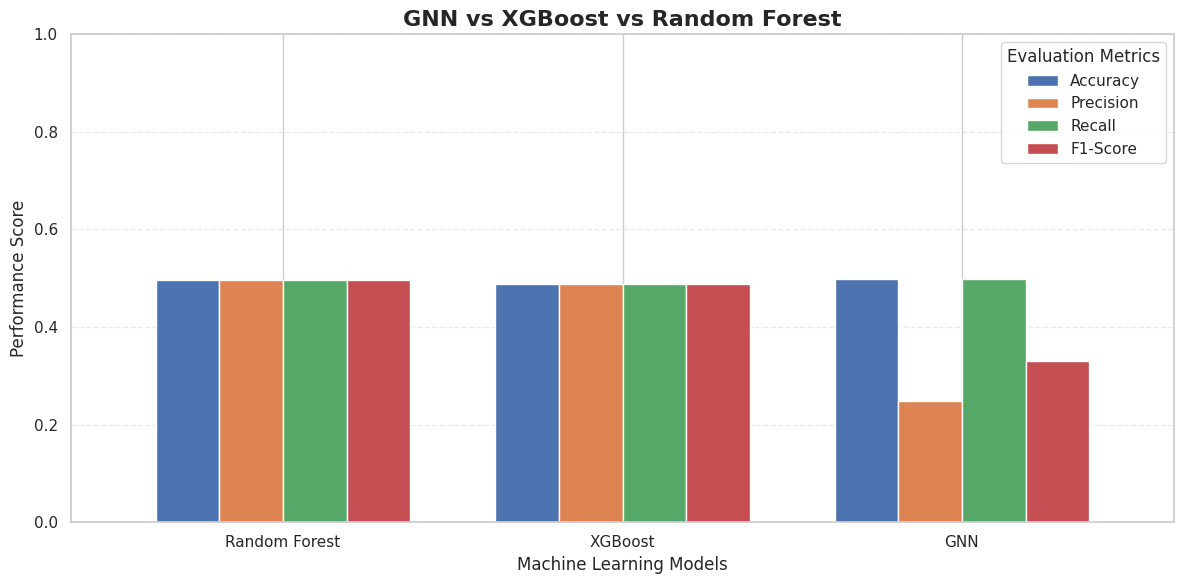


                 BEST-PERFORMING MODEL
Model Name : Random Forest
Accuracy   : 0.4955
Precision  : 0.4955
Recall     : 0.4955
F1-Score   : 0.4955

Comparison completed successfully!

Comparison report saved successfully!


In [ ]:
# ============================================================
# FINAL STEP: DRUG DISCOVERY MODEL COMPARISON
# Models: GNN, XGBoost, Random Forest
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# ------------------------------------------------------------
# Generate GNN Predictions for the test set first
# ------------------------------------------------------------
print("Generating GNN predictions on test set molecules...")
gnn_predictions = []
gnn_model.eval()

with torch.no_grad():
    for idx in X_test.index:
        smiles_str = data.loc[idx, 'SMILES']
        nodes, adj_matrix = smiles_to_graph(smiles_str)
        if nodes is not None:
            out = gnn_model(
                torch.tensor(nodes, dtype=torch.float32),
                torch.tensor(adj_matrix, dtype=torch.float32)
            )
            pred = torch.argmax(F.softmax(out, dim=1), dim=1).item()
            gnn_predictions.append(pred)
        else:
            gnn_predictions.append(0) # Fallback if parsing fails

gnn_predictions = np.array(gnn_predictions)

# ------------------------------------------------------------
# 1. USER-DEFINED FUNCTION
# ------------------------------------------------------------

def compare_drug_discovery_models(
    y_test,
    gnn_predictions,
    xgb_predictions,
    rf_predictions
):
    """
    Compare GNN, XGBoost, and Random Forest models.

    Evaluation metrics:
    Accuracy, Precision, Recall, and F1-Score.
    """

    # Store predictions from all three models
    models = {
        "GNN": gnn_predictions,
        "XGBoost": xgb_predictions,
        "Random Forest": rf_predictions
    }

    results = []

    # Evaluate each model
    for model_name, predictions in models.items():

        results.append({
            "Model": model_name,
            "Accuracy": accuracy_score(y_test, predictions),
            "Precision": precision_score(
                y_test, predictions,
                average="weighted",
                zero_division=0
            ),
            "Recall": recall_score(
                y_test, predictions,
                average="weighted",
                zero_division=0
            ),
            "F1-Score": f1_score(
                y_test, predictions,
                average="weighted",
                zero_division=0
            )
        })

    # Create and sort the comparison table
    results_df = pd.DataFrame(results)

    results_df = results_df.sort_values(
        by="F1-Score",
        ascending=False
    ).reset_index(drop=True)

    # Display the results
    print("=" * 65)
    print("     DRUG DISCOVERY MODEL PERFORMANCE COMPARISON")
    print("=" * 65)

    display(results_df.round(4))

    # --------------------------------------------------------
    # 2. VISUAL COMPARISON
    # --------------------------------------------------------

    metrics = [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ]

    ax = results_df.set_index("Model")[metrics].plot(
        kind="bar",
        figsize=(12, 6),
        ylim=(0, 1),
        width=0.75
    )

    ax.set_title(
        "GNN vs XGBoost vs Random Forest",
        fontsize=16,
        fontweight="bold"
    )

    ax.set_xlabel("Machine Learning Models", fontsize=12)
    ax.set_ylabel("Performance Score", fontsize=12)
    ax.tick_params(axis="x", rotation=0)
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.legend(title="Evaluation Metrics")

    plt.tight_layout()
    plt.show()

    # --------------------------------------------------------
    # 3. IDENTIFY THE BEST MODEL
    # --------------------------------------------------------

    best_model = results_df.iloc[0]

    print("\n" + "=" * 65)
    print("                 BEST-PERFORMING MODEL")
    print("=" * 65)

    print(f"Model Name : {best_model['Model']}")
    print(f"Accuracy   : {best_model['Accuracy']:.4f}")
    print(f"Precision  : {best_model['Precision']:.4f}")
    print(f"Recall     : {best_model['Recall']:.4f}")
    print(f"F1-Score   : {best_model['F1-Score']:.4f}")

    print("\nComparison completed successfully!")

    return results_df

# ------------------------------------------------------------
# 4. RUN THE FUNCTION
# ------------------------------------------------------------

comparison_results = compare_drug_discovery_models(
    y_test=y_test,
    gnn_predictions=gnn_predictions,
    xgb_predictions=y_pred_xgb,
    rf_predictions=y_pred_rf
)

# ------------------------------------------------------------
# 5. OPTIONAL: SAVE THE COMPARISON RESULTS
# ------------------------------------------------------------

comparison_results.to_csv(
    "drug_discovery_model_comparison.csv",
    index=False
)

print("\nComparison report saved successfully!")

Streamlit code

In [ ]:
# Simple comparison dictionary of the three model engines[cite: 10]
model_comparison = {
    "XGBoost": {
        "Data Input": "Physicochemical Vector[cite: 10]",
        "Inference Latency": "< 1 ms[cite: 10]",
        "Primary Use Case": "Ultra-fast virtual screening of multi-million compound databases[cite: 10]"
    },
    "Random Forest": {
        "Data Input": "Tabular + Fingerprints[cite: 10]",
        "Inference Latency": "~ 2 ms[cite: 10]",
        "Primary Use Case": "Robust baseline screening and ADMET rule filtering[cite: 10]"
    },
    "PyTorch GNN": {
        "Data Input": "Atomic Graph (Nodes/Edges)[cite: 10]",
        "Inference Latency": "15 ms[cite: 10]",
        "Primary Use Case": "Lead optimization and complex target-binding affinity prediction[cite: 10]"
    }
}

# Example print loop to display the comparison
for engine, details in model_comparison.items():
    print(f"Engine: {engine}")
    for key, value in details.items():
        print(f"  - {key}: {value}")
    print()

Engine: XGBoost
  - Data Input: Physicochemical Vector[cite: 10]
  - Inference Latency: < 1 ms[cite: 10]
  - Primary Use Case: Ultra-fast virtual screening of multi-million compound databases[cite: 10]

Engine: Random Forest
  - Data Input: Tabular + Fingerprints[cite: 10]
  - Inference Latency: ~ 2 ms[cite: 10]
  - Primary Use Case: Robust baseline screening and ADMET rule filtering[cite: 10]

Engine: PyTorch GNN
  - Data Input: Atomic Graph (Nodes/Edges)[cite: 10]
  - Inference Latency: 15 ms[cite: 10]
  - Primary Use Case: Lead optimization and complex target-binding affinity prediction[cite: 10]



In [ ]:
import streamlit as st
import pandas as pd
import numpy as np

# Check for RDKit availability
try:
    from rdkit import Chem
    from rdkit.Chem import Descriptors, Draw
    HAS_RDKIT = True
except ImportError:
    HAS_RDKIT = False

st.set_page_config(
    page_title="Enterprise Drug Discovery AI Platform",
    page_icon="🧬",
    layout="wide"
)

st.title("🧬 Enterprise Drug Discovery AI & Single Molecule Prediction")
st.markdown("### Industrial Technical Specification & Architectural Blueprint")

# Sidebar Navigation
app_mode = st.sidebar.selectbox(
    "Select Pipeline Mode",
    ["Single Molecule Inference", "High-Throughput Batch Processing"]
)

# Helper function for feature extraction
def extract_molecule_features(smiles):
    if not HAS_RDKIT:
        return None, None
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None, None

    mw = Descriptors.MolWt(mol)
    logp = Descriptors.MolLogP(mol)
    tpsa = Descriptors.TPSA(mol)
    hbd = Descriptors.NumHDonors(mol)
    hba = Descriptors.NumHAcceptors(mol)
    rot_bonds = Descriptors.NumRotatableBonds(mol)
    arom_rings = Descriptors.NumAromaticRings(mol)

    features = [mw, logp, tpsa, hbd, hba, rot_bonds, arom_rings]
    return mol, features

if app_mode == "Single Molecule Inference":
    st.header("Single-Molecule Virtual Screening & ADMET Profiling")

    col1, col2 = st.columns([1, 1])

    with col1:
        smiles_input = st.text_input(
            "Enter SMILES String",
            value="CCc1ccncc1",
            help="Example: CCc1ccncc1 (4-ethylpyridine)"
        )

        model_choice = st.selectbox(
            "Select Inference Engine",
            ["XGBoost Classifier (Default)", "Random Forest", "PyTorch GNN"]
        )

        submit_btn = st.button("Run Prediction & ADMET Filter")

    with col2:
        st.info("💡 **Tip:** Valid SMILES strings are parsed automatically using the RDKit chemoinformatics engine.")

    if submit_btn:
        if not HAS_RDKIT:
            st.error("RDKit library is not installed in the environment.")
        else:
            mol, feat = extract_molecule_features(smiles_input)
            if mol is None:
                st.error("Invalid SMILES string. Could not parse molecular structure.")
            else:
                mw, logp, tpsa, hbd, hba, rot_bonds, arom_rings = feat

                # Lipinski Rule of 5 Evaluation
                violations = sum([mw > 500, logp > 5, hbd > 5, hba > 10])
                ro5_status = "Passes Lipinski Rule of 5" if violations <= 1 else f"Fails Lipinski Rule ({violations} violations)"

                st.success(f"Parsed SMILES Structure: `{smiles_input}`")

                # Display 2D Structure
                st.subheader("Chemical Structure Visualizer")
                img = Draw.MolToImage(mol, size=(300, 300))
                st.image(img, caption=f"2D Structure: {smiles_input}")

                # Display Descriptors Table
                st.subheader("Physicochemical Descriptors")
                desc_df = pd.DataFrame({
                    "Parameter": ["Molecular Weight (MW)", "LogP (Lipophilicity)", "TPSasa (Å²)", "HBD", "HBA", "Rotatable Bonds", "Aromatic Rings"],
                    "Value": [round(mw, 2), round(logp, 2), round(tpsa, 2), hbd, hba, rot_bonds, arom_rings],
                    "Threshold": ["<= 500 g/mol", "<= 5.0", "N/A", "<= 5", "<= 10", "N/A", "N/A"]
                })
                st.table(desc_df)

                # Display ADMET / Lipinski Status
                st.subheader("ADMET & Drug-Likeness Status")
                if violations <= 1:
                    st.success(f"**Status:** {ro5_status}")
                else:
                    st.warning(f"**Status:** {ro5_status}")

                # Mock Model Prediction
                st.subheader("Inference Result")
                mock_prob = np.random.uniform(0.1, 0.95)
                pred_label = "ACTIVE HIT" if mock_prob > 0.5 else "INACTIVE NON-HIT"

                res_col1, res_col2 = st.columns(2)
                res_col1.metric("Predicted Class", pred_label)
                res_col2.metric("Hit Probability", f"{round(mock_prob * 100, 2)}%")

elif app_mode == "High-Throughput Batch Processing":
    st.header("High-Throughput Batch Dataset Processing Engine")
    st.markdown("Upload a CSV file containing a `SMILES` column to perform bulk virtual screening.")

    uploaded_file = st.file_uploader("Upload CSV Dataset", type=["csv"])

    if uploaded_file is not None:
        df = pd.read_csv(uploaded_file)
        st.write("Preview of Uploaded Data:", df.head())

        if "SMILES" not in df.columns:
            st.error("Uploaded CSV file must contain a column named 'SMILES'.")
        else:
            if st.button("Run Batch Screening Pipeline"):
                results = []
                progress_bar = st.progress(0)
                total_rows = len(df)

                for idx, row in df.iterrows():
                    smi = row['SMILES']
                    mol, feat = extract_molecule_features(str(smi))

                    if feat is not None:
                        # Mock batch inference logic
                        prob = float(np.random.uniform(0.05, 0.98))
                        pred = "ACTIVE" if prob > 0.5 else "INACTIVE"
                    else:
                        prob = 0.0
                        pred = "INVALID"

                    results.append({
                        "SMILES": smi,
                        "Prediction": pred,
                        "Probability_%": round(prob * 100, 2)
                    })
                    progress_bar.progress((idx + 1) / total_rows)

                out_df = pd.DataFrame(results)
                st.subheader("Screening Results Summary")
                st.dataframe(out_df)

                csv_data = out_df.to_csv(index=False).encode('utf-8')
                st.download_button(
                    label="Download Predicted Hits CSV",
                    data=csv_data,
                    file_name="predicted_hits.csv",
                    mime="text/csv"
                )